# 02 · 轻量 CNN 图像降噪

本实验训练一个小型残差卷积网络预测噪声，并将其与传统 Wavelet
降噪进行对比。训练图像来自 `scikit-image` 内置样例，训练时在线生成
高斯噪声，整个实验可在 CPU 上运行。

In [1]:
from pathlib import Path
import csv
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from skimage import data, img_as_float32, transform
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.restoration import denoise_wavelet
from torch import nn
from torch.utils.data import DataLoader, Dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, min(4, torch.get_num_threads())))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT = Path("outputs")
ARTIFACTS = Path("artifacts")
OUTPUT.mkdir(exist_ok=True)
ARTIFACTS.mkdir(exist_ok=True)
print("device:", DEVICE)

device: cpu


## 1. 合成训练集

In [2]:
def rgb_float(image, size=(256, 256)):
    image = img_as_float32(image)
    if image.ndim == 2:
        image = np.repeat(image[..., None], 3, axis=-1)
    if image.shape[-1] == 4:
        image = image[..., :3]
    return transform.resize(image, size, anti_aliasing=True).astype(np.float32)


train_images = [
    rgb_float(data.astronaut()),
    rgb_float(data.coffee()),
    rgb_float(data.chelsea()),
    rgb_float(data.rocket()),
    rgb_float(data.hubble_deep_field()),
]
test_image = rgb_float(data.camera())


class NoisyPatchDataset(Dataset):
    def __init__(self, images, length=384, patch=40, sigma=(0.02, 0.08)):
        self.images = images
        self.length = length
        self.patch = patch
        self.sigma = sigma

    def __len__(self):
        return self.length

    def __getitem__(self, index):
        rng = np.random.default_rng(SEED + index)
        image = self.images[index % len(self.images)]
        y = rng.integers(0, image.shape[0] - self.patch + 1)
        x = rng.integers(0, image.shape[1] - self.patch + 1)
        clean = image[y : y + self.patch, x : x + self.patch]
        sigma = rng.uniform(*self.sigma)
        noisy = np.clip(clean + rng.normal(0, sigma, clean.shape), 0, 1)
        clean = torch.from_numpy(clean.transpose(2, 0, 1).copy())
        noisy = torch.from_numpy(noisy.transpose(2, 0, 1).astype(np.float32))
        return noisy, clean


train_loader = DataLoader(
    NoisyPatchDataset(train_images), batch_size=24, shuffle=True, num_workers=0
)
print("training patches:", len(train_loader.dataset))

training patches: 384


## 2. TinyDnCNN

In [3]:
class TinyDnCNN(nn.Module):
    def __init__(self, channels=24, depth=5):
        super().__init__()
        layers = [nn.Conv2d(3, channels, 3, padding=1), nn.ReLU(inplace=True)]
        for _ in range(depth - 2):
            layers += [
                nn.Conv2d(channels, channels, 3, padding=1),
                nn.ReLU(inplace=True),
            ]
        layers.append(nn.Conv2d(channels, 3, 3, padding=1))
        self.net = nn.Sequential(*layers)

    def forward(self, noisy):
        predicted_noise = self.net(noisy)
        return torch.clamp(noisy - predicted_noise, 0, 1)


model = TinyDnCNN().to(DEVICE)
parameter_count = sum(p.numel() for p in model.parameters())
print(model)
print(f"parameters: {parameter_count:,}")

TinyDnCNN(
  (net): Sequential(
    (0): Conv2d(3, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU(inplace=True)
    (6): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(24, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
)
parameters: 16,947


## 3. 训练

In [4]:
optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)
loss_fn = nn.MSELoss()
history = []
epochs = 6
started = time.perf_counter()

model.train()
for epoch in range(epochs):
    total = 0.0
    for noisy, clean in train_loader:
        noisy, clean = noisy.to(DEVICE), clean.to(DEVICE)
        optimizer.zero_grad()
        denoised = model(noisy)
        loss = loss_fn(denoised, clean)
        loss.backward()
        optimizer.step()
        total += loss.item() * noisy.size(0)
    epoch_loss = total / len(train_loader.dataset)
    history.append(epoch_loss)
    print(f"epoch {epoch + 1}/{epochs} - MSE: {epoch_loss:.6f}")

elapsed = time.perf_counter() - started
torch.save(
    {
        "model_state": model.state_dict(),
        "parameters": parameter_count,
        "epochs": epochs,
        "seed": SEED,
    },
    ARTIFACTS / "tiny_dncnn.pt",
)
print(f"training time: {elapsed:.1f}s")

epoch 1/6 - MSE: 0.002636
epoch 2/6 - MSE: 0.002351
epoch 3/6 - MSE: 0.001932
epoch 4/6 - MSE: 0.001538
epoch 5/6 - MSE: 0.001170
epoch 6/6 - MSE: 0.000956
training time: 2.1s


## 4. 与传统降噪比较

In [5]:
eval_rng = np.random.default_rng(2026)
sigma = 0.06
noisy = np.clip(
    test_image + eval_rng.normal(0, sigma, test_image.shape), 0, 1
).astype(np.float32)
wavelet = denoise_wavelet(
    noisy, channel_axis=-1, rescale_sigma=True, method="BayesShrink"
).astype(np.float32)

model.eval()
with torch.no_grad():
    tensor = torch.from_numpy(noisy.transpose(2, 0, 1))[None].to(DEVICE)
    cnn = model(tensor)[0].cpu().numpy().transpose(1, 2, 0)


def metrics(image):
    return {
        "PSNR (dB)": peak_signal_noise_ratio(test_image, image, data_range=1),
        "SSIM": structural_similarity(
            test_image, image, channel_axis=-1, data_range=1
        ),
    }


results = {
    "Noisy": metrics(noisy),
    "Wavelet": metrics(wavelet),
    "TinyDnCNN": metrics(cnn),
}
for name, values in results.items():
    print(
        f'{name:>10} | PSNR {values["PSNR (dB)"]:.2f} dB | '
        f'SSIM {values["SSIM"]:.4f}'
    )

with (OUTPUT / "denoising_metrics.csv").open(
    "w", newline="", encoding="utf-8"
) as f:
    writer = csv.writer(f)
    writer.writerow(["Method", "PSNR (dB)", "SSIM"])
    for name, values in results.items():
        writer.writerow([name, values["PSNR (dB)"], values["SSIM"]])

     Noisy | PSNR 24.63 dB | SSIM 0.4581
   Wavelet | PSNR 29.41 dB | SSIM 0.7274
 TinyDnCNN | PSNR 30.72 dB | SSIM 0.7471


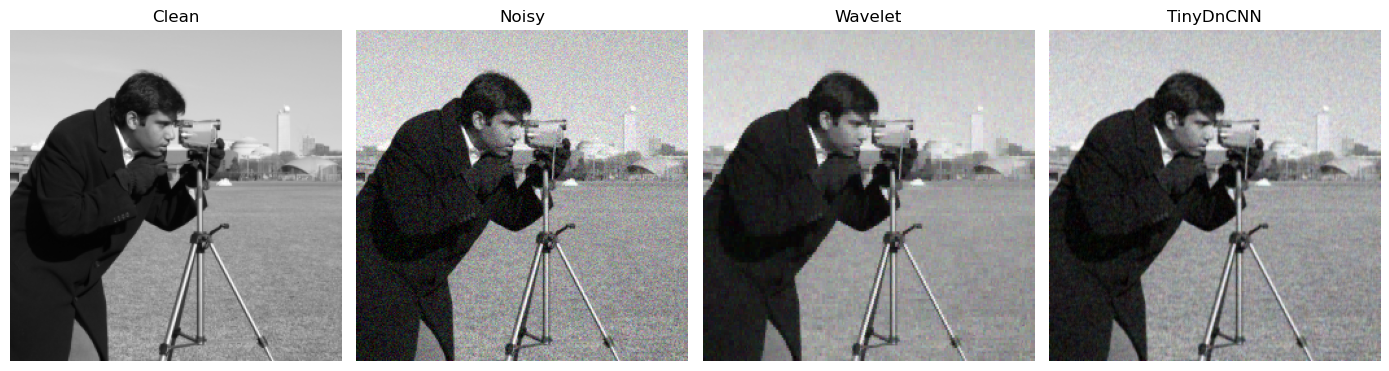

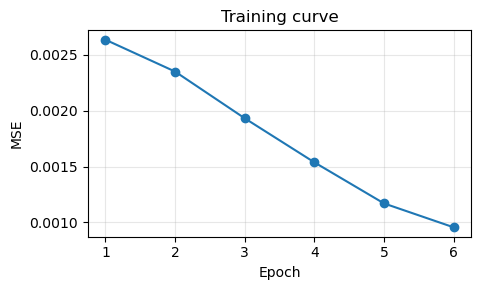

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (title, image) in zip(
    axes,
    [
        ("Clean", test_image),
        ("Noisy", noisy),
        ("Wavelet", wavelet),
        ("TinyDnCNN", cnn),
    ],
):
    ax.imshow(np.clip(image, 0, 1))
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT / "denoising_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

plt.figure(figsize=(5, 3))
plt.plot(range(1, epochs + 1), history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training curve")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT / "training_curve.png", dpi=160, bbox_inches="tight")
plt.show()

## 结论

- TinyDnCNN 使用残差学习预测噪声；
- 实验记录实际训练时间、参数量、PSNR 与 SSIM；

可进一步使用真实 RAW / SIDD 数据集训练，并进行 ONNX 或移动端部署。